In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python Sales Analysis Project Started ✅")

Python Sales Analysis Project Started ✅


In [ ]:
data = {
    "order_id": [1001,1002,1003,1004,1005,1006,1007,1008,1009,1010],
    "order_date": [
        "2026-01-05","2026-01-08","2026-01-12","2026-02-03","2026-02-10",
        "2026-02-15","2026-03-02","2026-03-09","2026-03-18","2026-03-25"
    ],
    "customer_name": [
        "Rahul Sharma","Priya Patil","Amit Kumar","Sneha Joshi","Rohan Singh",
        "Neha Deshmukh","Vikas Shah","Pooja Mehta","Karan Gupta","Anjali Kulkarni"
    ],
    "product": [
        "Laptop","Mobile","Headphones","Monitor","Keyboard",
        "Laptop","Mouse","Mobile","Monitor","Keyboard"
    ],
    "category": [
        "Electronics","Electronics","Accessories","Electronics","Accessories",
        "Electronics","Accessories","Electronics","Electronics","Accessories"
    ],
    "quantity": [1,2,3,2,4,1,5,2,1,3],
    "price": [55000,25000,2000,15000,1500,60000,800,30000,18000,1800],
    "sales_amount": [55000,50000,6000,30000,6000,60000,4000,60000,18000,5400],
    "city": [
        "Pune","Mumbai","Delhi","Pune","Bangalore",
        "Mumbai","Ahmedabad","Pune","Delhi","Mumbai"
    ]
}

df = pd.DataFrame(data)

df["order_date"] = pd.to_datetime(df["order_date"])

df

,order_id,order_date,customer_name,product,category,quantity,price,sales_amount,city
0,1001,2026-01-05,Rahul Sharma,Laptop,Electronics,1,55000,55000,Pune
1,1002,2026-01-08,Priya Patil,Mobile,Electronics,2,25000,50000,Mumbai
2,1003,2026-01-12,Amit Kumar,Headphones,Accessories,3,2000,6000,Delhi
3,1004,2026-02-03,Sneha Joshi,Monitor,Electronics,2,15000,30000,Pune
4,1005,2026-02-10,Rohan Singh,Keyboard,Accessories,4,1500,6000,Bangalore
5,1006,2026-02-15,Neha Deshmukh,Laptop,Electronics,1,60000,60000,Mumbai
6,1007,2026-03-02,Vikas Shah,Mouse,Accessories,5,800,4000,Ahmedabad
7,1008,2026-03-09,Pooja Mehta,Mobile,Electronics,2,30000,60000,Pune
8,1009,2026-03-18,Karan Gupta,Monitor,Electronics,1,18000,18000,Delhi
9,1010,2026-03-25,Anjali Kulkarni,Keyboard,Accessories,3,1800,5400,Mumbai


In [ ]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

Rows: 10
Columns: 9

Column names:
['order_id', 'order_date', 'customer_name', 'product', 'category', 'quantity', 'price', 'sales_amount', 'city']


In [ ]:
total_revenue = df["sales_amount"].sum()
total_orders = df["order_id"].count()
total_units = df["quantity"].sum()
average_order_value = df["sales_amount"].mean()
highest_order = df["sales_amount"].max()
lowest_order = df["sales_amount"].min()

print("----- SALES KPIs -----")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Units Sold: {total_units}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Highest Order: ₹{highest_order:,.2f}")
print(f"Lowest Order: ₹{lowest_order:,.2f}")

----- SALES KPIs -----
Total Revenue: ₹294,400.00
Total Orders: 10
Total Units Sold: 24
Average Order Value: ₹29,440.00
Highest Order: ₹60,000.00
Lowest Order: ₹4,000.00


In [ ]:
df["month"] = df["order_date"].dt.strftime("%B")

monthly_sales = (
    df.groupby(df["order_date"].dt.month)
      .agg(
          month=("month", "first"),
          total_sales=("sales_amount", "sum")
      )
      .reset_index(drop=True)
)

monthly_sales

,month,total_sales
0,January,111000
1,February,96000
2,March,87400


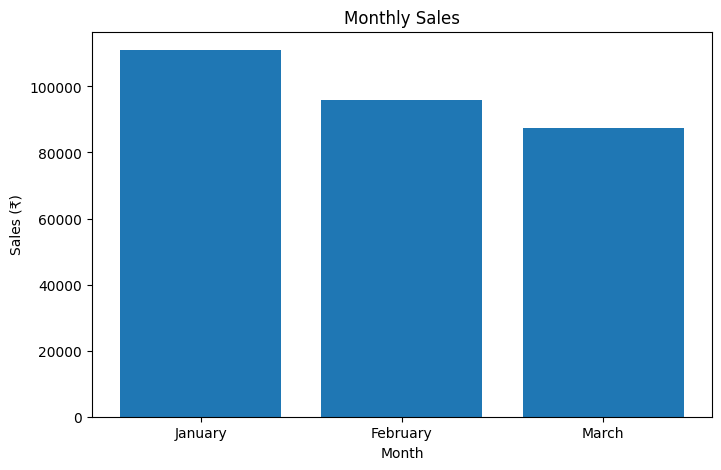

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(monthly_sales["month"], monthly_sales["total_sales"])

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
product_sales = (
    df.groupby("product", as_index=False)["sales_amount"]
      .sum()
      .sort_values("sales_amount", ascending=False)
)

product_sales

,product,sales_amount
2,Laptop,115000
3,Mobile,110000
4,Monitor,48000
1,Keyboard,11400
0,Headphones,6000
5,Mouse,4000


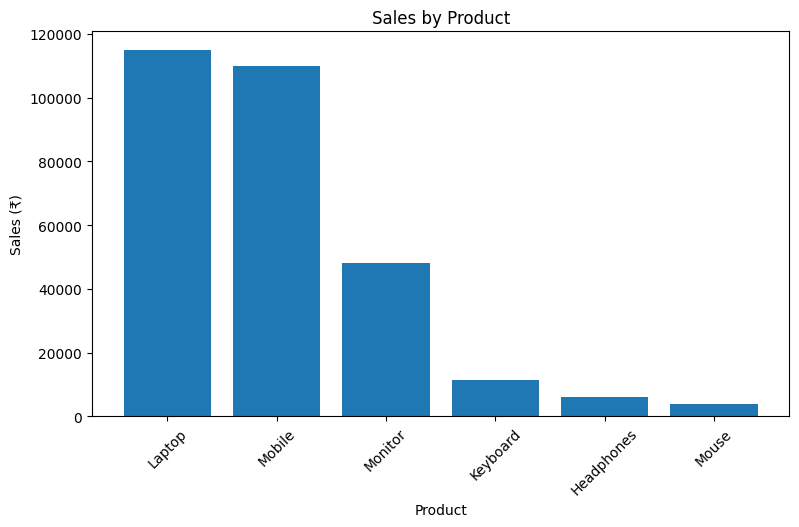

In [ ]:
plt.figure(figsize=(9,5))

plt.bar(product_sales["product"], product_sales["sales_amount"])

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
city_sales = (
    df.groupby("city", as_index=False)
      .agg(
          total_sales=("sales_amount", "sum"),
          total_units=("quantity", "sum")
      )
      .sort_values("total_sales", ascending=False)
)

city_sales

,city,total_sales,total_units
4,Pune,145000,5
3,Mumbai,115400,6
2,Delhi,24000,4
1,Bangalore,6000,4
0,Ahmedabad,4000,5


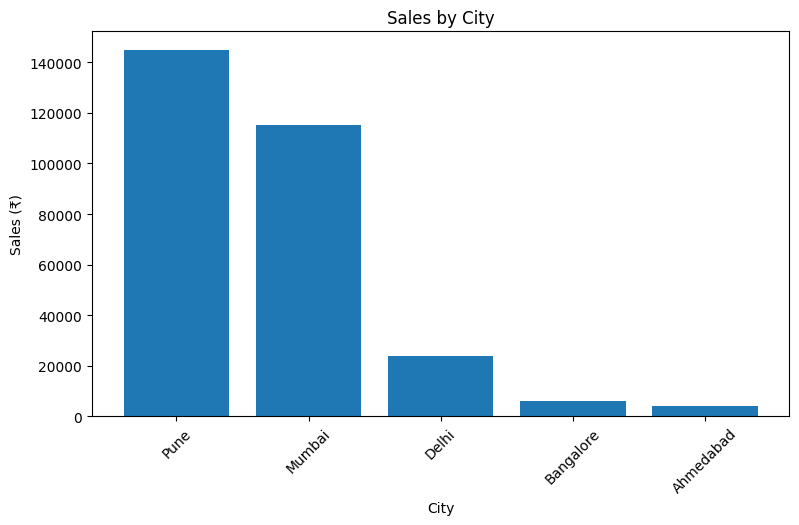

In [ ]:
plt.figure(figsize=(9,5))

plt.bar(city_sales["city"], city_sales["total_sales"])

plt.title("Sales by City")
plt.xlabel("City")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
category_sales = (
    df.groupby("category", as_index=False)["sales_amount"]
      .sum()
      .sort_values("sales_amount", ascending=False)
)

category_sales

,category,sales_amount
1,Electronics,273000
0,Accessories,21400


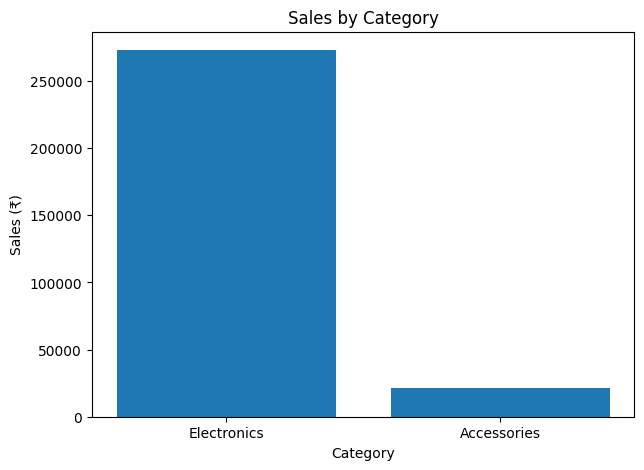

In [ ]:
plt.figure(figsize=(7,5))

plt.bar(category_sales["category"], category_sales["sales_amount"])

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales (₹)")

plt.show()

In [ ]:
customer_sales = (
    df.groupby("customer_name", as_index=False)["sales_amount"]
      .sum()
      .sort_values("sales_amount", ascending=False)
)

customer_sales

,customer_name,sales_amount
4,Pooja Mehta,60000
3,Neha Deshmukh,60000
6,Rahul Sharma,55000
5,Priya Patil,50000
8,Sneha Joshi,30000
2,Karan Gupta,18000
7,Rohan Singh,6000
0,Amit Kumar,6000
1,Anjali Kulkarni,5400
9,Vikas Shah,4000


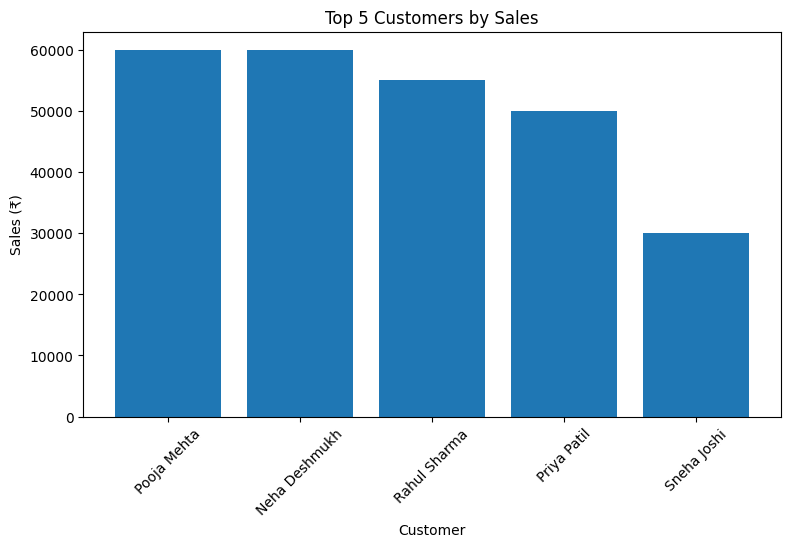

In [ ]:
top_customers = customer_sales.head(5)

plt.figure(figsize=(9,5))

plt.bar(top_customers["customer_name"], top_customers["sales_amount"])

plt.title("Top 5 Customers by Sales")
plt.xlabel("Customer")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)

plt.show()

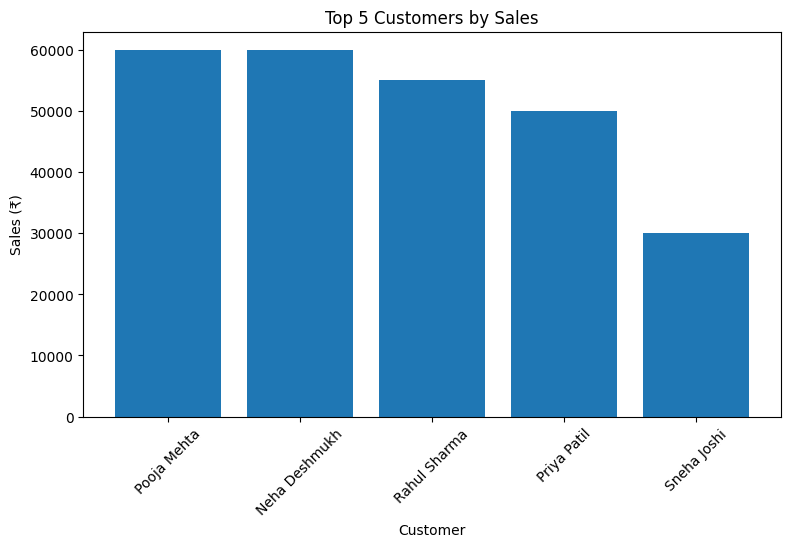

In [ ]:
top_customers = customer_sales.head(5)

plt.figure(figsize=(9,5))

plt.bar(top_customers["customer_name"], top_customers["sales_amount"])

plt.title("Top 5 Customers by Sales")
plt.xlabel("Customer")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
product_quantity = (
    df.groupby("product", as_index=False)["quantity"]
      .sum()
      .sort_values("quantity", ascending=False)
)

product_quantity

,product,quantity
1,Keyboard,7
5,Mouse,5
3,Mobile,4
0,Headphones,3
4,Monitor,3
2,Laptop,2


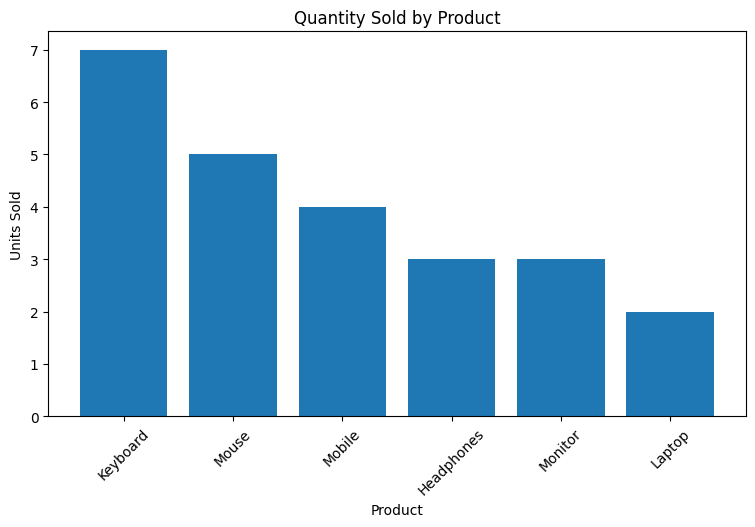

In [ ]:
plt.figure(figsize=(9,5))

plt.bar(product_quantity["product"], product_quantity["quantity"])

plt.title("Quantity Sold by Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)

plt.show()

In [ ]:
product_performance = (
    df.groupby("product", as_index=False)
      .agg(
          total_quantity=("quantity", "sum"),
          total_sales=("sales_amount", "sum")
      )
      .sort_values("total_sales", ascending=False)
)

product_performance

,product,total_quantity,total_sales
2,Laptop,2,115000
3,Mobile,4,110000
4,Monitor,3,48000
1,Keyboard,7,11400
0,Headphones,3,6000
5,Mouse,5,4000


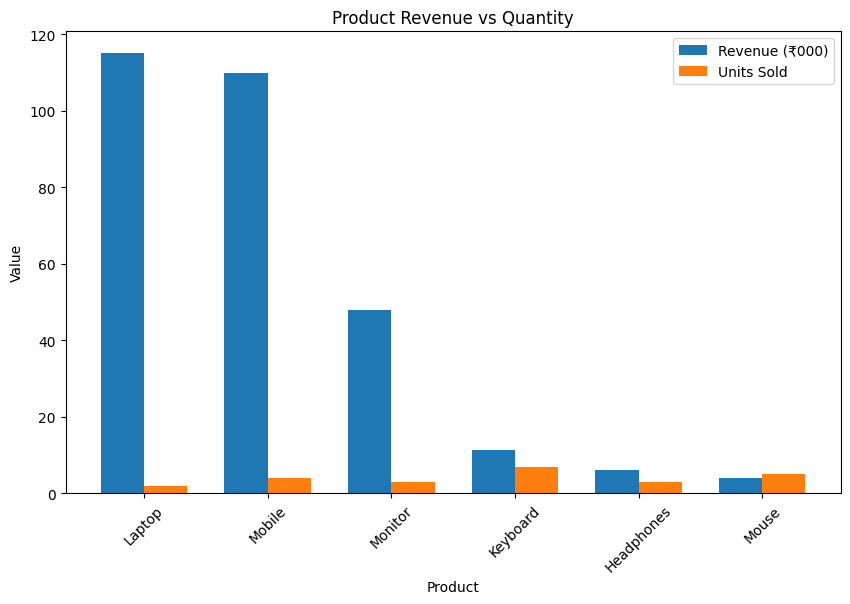

In [ ]:
plt.figure(figsize=(10, 6))

x = np.arange(len(product_performance))
width = 0.35

plt.bar(
    x - width/2,
    product_performance["total_sales"] / 1000,
    width,
    label="Revenue (₹000)"
)

plt.bar(
    x + width/2,
    product_performance["total_quantity"],
    width,
    label="Units Sold"
)

plt.title("Product Revenue vs Quantity")
plt.xlabel("Product")
plt.ylabel("Value")
plt.xticks(x, product_performance["product"], rotation=45)
plt.legend()

plt.show()

In [ ]:
print("==========================================")
print("SALES PERFORMANCE ANALYSIS - PYTHON")
print("==========================================")

print(f"Total Revenue      : ₹{df['sales_amount'].sum():,.2f}")
print(f"Total Orders       : {df['order_id'].count()}")
print(f"Total Units Sold   : {df['quantity'].sum()}")
print(f"Average Order Value: ₹{df['sales_amount'].mean():,.2f}")

top_product = df.groupby("product")["sales_amount"].sum().idxmax()
top_product_sales = df.groupby("product")["sales_amount"].sum().max()

top_city = df.groupby("city")["sales_amount"].sum().idxmax()
top_city_sales = df.groupby("city")["sales_amount"].sum().max()

top_category = df.groupby("category")["sales_amount"].sum().idxmax()
top_category_sales = df.groupby("category")["sales_amount"].sum().max()

top_quantity_product = df.groupby("product")["quantity"].sum().idxmax()
top_quantity = df.groupby("product")["quantity"].sum().max()

print("\nKEY INSIGHTS")
print(f"Top Revenue Product : {top_product} (₹{top_product_sales:,.2f})")
print(f"Top Revenue City    : {top_city} (₹{top_city_sales:,.2f})")
print(f"Top Category        : {top_category} (₹{top_category_sales:,.2f})")
print(f"Top Quantity Product: {top_quantity_product} ({top_quantity} units)")

SALES PERFORMANCE ANALYSIS - PYTHON
Total Revenue      : ₹294,400.00
Total Orders       : 10
Total Units Sold   : 24
Average Order Value: ₹29,440.00

KEY INSIGHTS
Top Revenue Product : Laptop (₹115,000.00)
Top Revenue City    : Pune (₹145,000.00)
Top Category        : Electronics (₹273,000.00)
Top Quantity Product: Keyboard (7 units)
